# 第一讲 PPT 课后作业

> **PPT 第 53 页「课后作业…」**
>
> 使用以下两个文本片段，作为练习样例，按照要求，完成本讲学的**三个小练习**：
>
> 1. “曾经有一份真诚的爱情摆在我的面前，我没有珍惜，等到失去的时候才追悔莫及，人世间最痛苦的事情莫过于此。如果上天能够给我一个重新来过的机会，我会对那个女孩子说三个字：‘我爱你’。如果非要给这份爱加上一个期限，我希望是，一万年”
> 2. “LSTM（Long Short-Term Memory）是长短期记忆网络，是一种时间递归神经网络，适合于处理和预测时间序列中间隔和延迟相对较长的重要事件。”
>
> **PPT 第 54 页「第一讲 总结」**
>
> 作业：学习使用在线“微词云”系统；安装 python（anaconda）；完成课后编程作业 001-004，四份代码。

“三个小练习”对应的就是课堂演示的三步：**基本分词 → 加载用户词典 → 加载停用词表**
（PPT 第 48–52 页）。本 notebook 按这个顺序做，并补上第 54 页提到的“微词云”环节
（这里用本地 `wordcloud` 实现同样的效果，不需要联网上传文本）。

## 0 环境准备

如果本机还没装 jieba / wordcloud，取消下面这行的注释再运行：

In [1]:
# !pip install jieba wordcloud snownlp -i https://pypi.tuna.tsinghua.edu.cn/simple

In [2]:
import jieba
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from matplotlib import font_manager
from wordcloud import WordCloud

# Windows 用微软雅黑；课程示例里是 mac 的 'Heiti TC'
font_manager.fontManager.addfont('C:/Windows/Fonts/msyh.ttc')
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
FONT_PATH = 'C:/Windows/Fonts/msyh.ttc'

print('jieba', jieba.__version__)

jieba 0.42.1


In [3]:
# 两个练习样例（PPT 第 53 页原文）
text1 = '曾经有一份真诚的爱情摆在我的面前，我没有珍惜，等到失去的时候才追悔莫及，人世间最痛苦的事情莫过于此。如果上天能够给我一个重新来过的机会，我会对那个女孩子说三个字：‘我爱你’。如果非要给这份爱加上一个期限，我希望是，一万年'
text2 = 'LSTM（Long Short-Term Memory）是长短期记忆网络，是一种时间递归神经网络，适合于处理和预测时间序列中间隔和延迟相对较长的重要事件。'

print('样例1 长度：', len(text1), '字')
print('样例2 长度：', len(text2), '字')

样例1 长度： 110 字
样例2 长度： 77 字


## 练习一：基本分词

`jieba.cut()` 返回的是**生成器**，用 `join` 把结果串起来看最直观。
PPT 第 28–30 页讲了中文为什么必须分词：**汉语没有空格分隔**，
`南京市长江大桥` 既可能是「南京市长 / 江大桥」，也可能是「南京市 / 长江大桥」。

In [4]:
seg1 = jieba.cut(text1)
print('样例1（用 $ 连接）：')
print('$'.join(seg1))

Building prefix dict from the default dictionary ...


Loading model from cache C:\Users\34669\AppData\Local\Temp\jieba.cache


样例1（用 $ 连接）：


Loading model cost 0.305 seconds.


Prefix dict has been built successfully.


曾经$有$一份$真诚$的$爱情$摆在$我$的$面前$，$我$没有$珍惜$，$等到$失去$的$时候$才$追悔莫及$，$人世间$最$痛苦$的$事情$莫过于此$。$如果$上天$能够$给$我$一个$重新$来$过$的$机会$，$我会$对$那个$女孩子$说$三个$字$：$‘$我爱你$’$。$如果$非要$给$这份$爱$加上$一个$期限$，$我$希望$是$，$一万年


In [5]:
seg2 = jieba.cut(text2)
print('样例2（用 @ 连接）：')
print('@'.join(seg2))

样例2（用 @ 连接）：
LSTM@（@Long@ @Short@-@Term@ @Memory@）@是@长短期@记忆@网络@，@是@一种@时间@递归@神经网络@，@适合@于@处理@和@预测@时间@序列@中@间隔@和@延迟@相对@较长@的@重要@事件@。


In [6]:
# 量化一下：分成多少个词？有多少个不同的词？
w1, w2 = list(jieba.cut(text1)), list(jieba.cut(text2))
print(f'样例1：共 {len(w1)} 个 token，去重后 {len(set(w1))} 个')
print(f'样例2：共 {len(w2)} 个 token，去重后 {len(set(w2))} 个')

样例1：共 67 个 token，去重后 51 个
样例2：共 38 个 token，去重后 33 个


**观察**：样例 1 里 `爱情`、`珍惜`、`追悔莫及` 这些词都切对了；
但 `摆在` 被当成一个词、`重新`/`来`/`过` 被拆成三段——这正是 PPT 第 31–32 页说的
**分词歧义**与**分词不一致**。

样例 2 的问题更明显：`LSTM` 被切成 `L S T M`，`Long Short-Term Memory` 被空格和连字符切碎，
`长短期` / `记忆` / `网络` 被拆开。原因是**这些词不在 jieba 的默认词典里**（未登录词）。

## 练习二：加载用户词典

针对样例 2，把「长短期记忆网络」「时间递归神经网络」这类术语加进用户词典，
看能不能整体切出来。本文件夹的 `dict.txt` 里正好有这几个词：

In [7]:
# 先看看 dict.txt 里有什么
with open('dict.txt', 'r', encoding='utf-8') as f:
    dict_words = [line.strip().lstrip('\ufeff') for line in f if line.strip()]

print(f'dict.txt 共 {len(dict_words)} 个词：')
for w in dict_words:
    print('  ', w)

dict.txt 共 13 个词：
   特朗普
   南京工业最好大学
   永辉超市
   有点人性
   深度学习
   Long Short-Term Memory
   中船重工集团公司
   中国工程院院士
   二次元小魔仙
   长短期记忆网络
   时间递归神经网络
   数据挖掘与机器学习
   太有意思了


In [8]:
# 加词典之前，先记下样例2 的分词结果（此时还没加载用户词典）
before_dict = list(jieba.cut(text2))
print('加词典前：', '/'.join(before_dict))

加词典前： LSTM/（/Long/ /Short/-/Term/ /Memory/）/是/长短期/记忆/网络/，/是/一种/时间/递归/神经网络/，/适合/于/处理/和/预测/时间/序列/中/间隔/和/延迟/相对/较长/的/重要/事件/。


In [9]:
jieba.load_userdict('dict.txt')   # 载入用户词典

after_dict = list(jieba.cut(text2))
print('加词典后：', '/'.join(after_dict))

加词典后： LSTM/（/Long/ /Short/-/Term/ /Memory/）/是/长短期记忆网络/，/是/一种/时间递归神经网络/，/适合/于/处理/和/预测/时间/序列/中/间隔/和/延迟/相对/较长/的/重要/事件/。


In [10]:
# 对比：词典到底修好了哪些地方
print(f'词数：{len(before_dict)} → {len(after_dict)}（少了 {len(before_dict) - len(after_dict)} 个，碎词被合并）')

added = sorted(set(after_dict) - set(before_dict), key=len, reverse=True)
removed = sorted(set(before_dict) - set(after_dict), key=len, reverse=True)
print('\n新出现的完整词：', added)
print('消失的碎词    ：', removed)

词数：38 → 34（少了 4 个，碎词被合并）

新出现的完整词： ['时间递归神经网络', '长短期记忆网络']
消失的碎词    ： ['神经网络', '长短期', '递归', '记忆', '网络']


**结论**：`长短期记忆网络`、`时间递归神经网络` 都能**整体切出**了——这就是用户词典的作用，
也正是 PPT 第 31 页「未登录词（out-of-vocabulary）」问题的解法。

但注意：`LSTM` 里的英文和括号**不会**因为加中文词典而变好，
因为 `LSTM` 是英文缩写，需要另外加词，或者干脆保留英文原样（后面做实体抽取时反而更好用）。

## 练习三：加载停用词表

针对样例 1，希望结果是：**结果中不再出现「的、是、了」这类虚词，以及标点符号**。

In [11]:
with open('stop_words.txt', 'r', encoding='utf-8') as f:
    stopwords = [line.strip() for line in f if line.strip()]

print('停用词表内容：', stopwords)

停用词表内容： ['的', '了', '是', '啊', '、', '，', '。', '停用']


In [12]:
seg1_again = jieba.cut(text1)

final = ''
for seg in seg1_again:
    if seg not in stopwords:
        final += seg + '/'

print('过滤后（课程写法，末尾会多一个 /）：')
print(final)

过滤后（课程写法，末尾会多一个 /）：
曾经/有/一份/真诚/爱情/摆在/我/面前/我/没有/珍惜/等到/失去/时候/才/追悔莫及/人世间/最/痛苦/事情/莫过于此/如果/上天/能够/给/我/一个/重新/来/过/机会/我会/对/那个/女孩子/说/三个/字/：/‘/我爱你/’/如果/非要/给/这份/爱/加上/一个/期限/我/希望/一万年/


In [13]:
# 更规范的写法：用列表 + join，不会多出末尾的分隔符
kept = [w for w in jieba.cut(text1) if w not in stopwords]
print('/'.join(kept))

print(f'\n过滤前 {len(list(jieba.cut(text1)))} 个 token → 过滤后 {len(kept)} 个')
print('被去掉的词：', [w for w in jieba.cut(text1) if w in stopwords])

曾经/有/一份/真诚/爱情/摆在/我/面前/我/没有/珍惜/等到/失去/时候/才/追悔莫及/人世间/最/痛苦/事情/莫过于此/如果/上天/能够/给/我/一个/重新/来/过/机会/我会/对/那个/女孩子/说/三个/字/：/‘/我爱你/’/如果/非要/给/这份/爱/加上/一个/期限/我/希望/一万年

过滤前 67 个 token → 过滤后 53 个
被去掉的词： ['的', '的', '，', '，', '的', '，', '的', '。', '的', '，', '。', '，', '是', '，']


**结论**：`的`、`，`、`。` 这些词确实被去掉了，剩下的是有信息量的实词。

不过这份停用词表只有 8 个词（`的 了 是 啊 、 ， 。 停用`），所以 `我`、`如果`、`一个`
这类词还在。**真实的停用词表通常有几百上千个词**——这也是第 2 讲词频统计时要处理的问题。

## 练习四（PPT 第 54 页）：微词云——把分词结果做成词云

PPT 要求「学习使用在线微词云系统」。在线工具需要上传文本、依赖网络，
这里用本地 `wordcloud` 做同样的事，结果可复现、也不上传数据。

先看两个样例的**词频分布**（词云就是按词频决定字号大小）：

In [14]:
# 词频统计前先去停用词和标点，否则「的」「，」会占满画面
EXTRA = {'\n', ' ', '，', '。', '、', '：', '；', '‘', '’', '“', '”', '（', '）', '(', ')'}

def freq_table(text, topn=12):
    words = [w for w in jieba.cut(text) if w.strip() and w not in stopwords and w not in EXTRA and len(w) > 1]
    return Counter(words).most_common(topn)

for name, text in [('样例1', text1), ('样例2', text2)]:
    table = freq_table(text)
    print(f'--- {name} 词频 Top{len(table)} ---')
    for w, n in table:
        print(f'  {w:<10s} {n}')
    print()

--- 样例1 词频 Top12 ---
  如果         2
  一个         2
  曾经         1
  一份         1
  真诚         1
  爱情         1
  摆在         1
  面前         1
  没有         1
  珍惜         1
  等到         1
  失去         1

--- 样例2 词频 Top12 ---
  LSTM       1
  Long       1
  Short      1
  Term       1
  Memory     1
  长短期记忆网络    1
  一种         1
  时间递归神经网络   1
  适合         1
  处理         1
  预测         1
  时间         1



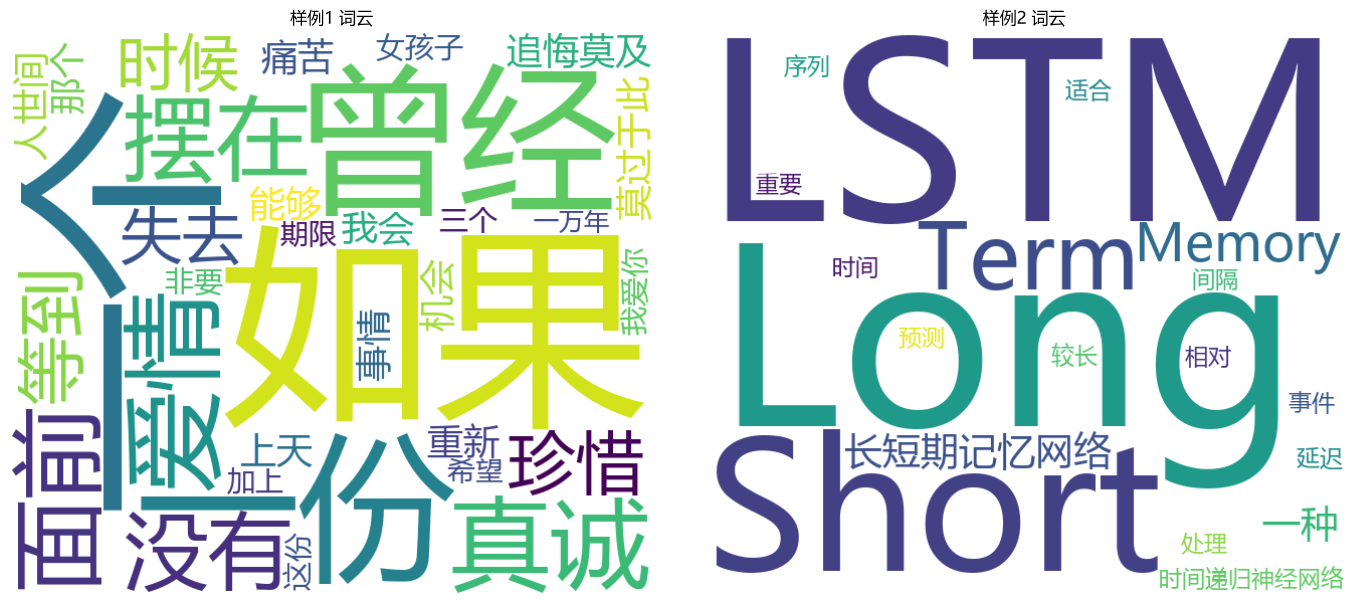

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, text) in zip(axes, [('样例1', text1), ('样例2', text2)]):
    freq = dict(freq_table(text, topn=60))
    wc = WordCloud(font_path=FONT_PATH, width=640, height=560,
                   background_color='white', max_words=60).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'{name} 词云', fontsize=12)

plt.tight_layout()
plt.show()

**⚠️ 这两张词云要小心解读**：两段文本都只有一两百字，绝大多数词的词频都是 1，
词云里字号几乎没有差别，谁大谁小更多取决于**排版时先放谁**，而不是词频高低。
所以在**短文本**上，词频条形图比词云更可信——下面是同样两份数据的条形图。

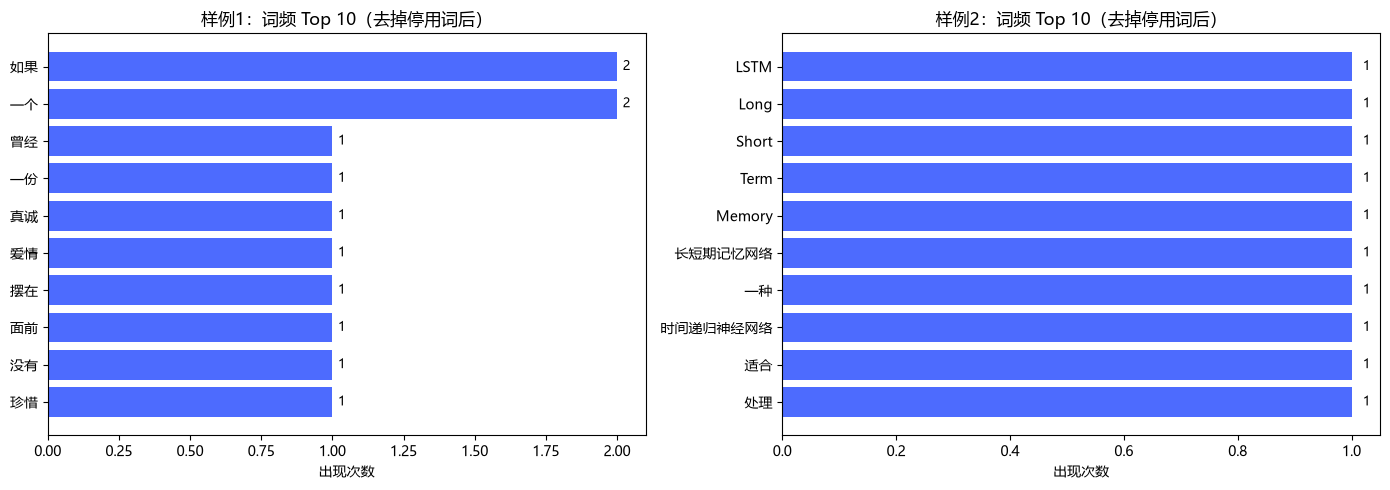

样例1 里除「如果」「一个」外全部只出现 1 次；样例2 每个词也只出现 1 次。
→ 短文本的「高频词」意义有限，词云更适合长文本（比如 PPT 里 Hinton 的百科词条）。


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, text) in zip(axes, [('样例1', text1), ('样例2', text2)]):
    data = freq_table(text, topn=10)[::-1]
    labels, values = [w for w, _ in data], [n for _, n in data]
    bars = ax.barh(labels, values, color='#4d6bfe')
    ax.set_xlabel('出现次数')
    ax.set_title(f'{name}：词频 Top 10（去掉停用词后）', fontsize=12)
    for bar, val in zip(bars, values):
        ax.text(val + 0.02, bar.get_y() + bar.get_height() / 2, str(val), va='center', fontsize=9)

plt.tight_layout()
plt.show()

print('样例1 里除「如果」「一个」外全部只出现 1 次；样例2 每个词也只出现 1 次。')
print('→ 短文本的「高频词」意义有限，词云更适合长文本（比如 PPT 里 Hinton 的百科词条）。')

**和在线微词云对比**：功能是一样的——分词、去停用词、按词频画词云。
本地做的额外好处是：① 数字可复现；② 文本不上传；③ 可以自己控制停用词表。

**注意一个细节**：`我` 是单字，被 `len(w) > 1` 过滤掉了，所以词云里看不到它。
如果不想过滤单字，把 `freq_table` 里的 `len(w) > 1` 去掉即可——
在线工具通常也会保留单字，只是内置停用词表更全，会把 `我`、`你`、`他` 也一并去掉。

## 附加：jieba 与 SnowNLP 对比（PPT 第 52 页）

课堂上老师演示过两者差异，这里用同样的两个样例再跑一次，看结果差异。

In [17]:
from snownlp import SnowNLP

for name, text in [('样例1', text1), ('样例2', text2)]:
    s = SnowNLP(text)
    print(f'--- {name} ---')
    print('jieba  :', '/'.join(list(jieba.cut(text))[:25]), '…')
    print('SnowNLP:', '/'.join(s.words[:25]), '…')
    print()

--- 样例1 ---
jieba  : 曾经/有/一份/真诚/的/爱情/摆在/我/的/面前/，/我/没有/珍惜/，/等到/失去/的/时候/才/追悔莫及/，/人世间/最/痛苦 …
SnowNLP: 曾经/有/一/份/真诚/的/爱情/摆/在/我/的/面前/，/我/没有/珍惜/，/等到/失去/的/时候/才/追悔莫及/，/人 …

--- 样例2 ---
jieba  : LSTM/（/Long/ /Short/-/Term/ /Memory/）/是/长短期记忆网络/，/是/一种/时间递归神经网络/，/适合/于/处理/和/预测/时间/序列/中 …
SnowNLP: LSTM（Long/Short-Term/Memory）/是/长短期/记忆/网络/，/是/一/种/时间/递/归/神经/网络/，/适合/于/处理/和/预测/时间/序列/中 …



**结论**：SnowNLP 的切分明显更碎，对中文长词、专有名词的处理不如 jieba——
因为它是面向**情感分析**的小型类库，词典规模有限。
课程结论「中文分词用 jieba」在这里得到了验证。

简单说，三个小练习各自解决一类问题：

| 练习 | 手段 | 解决的问题 |
|---|---|---|
| 一、基本分词 | `jieba.cut` | 让中文变成一个个词（无分隔符语言的根本问题） |
| 二、用户词典 | `load_userdict` | **未登录词**：术语、专有名词切不准 |
| 三、停用词表 | 过滤列表 | 虚词、标点干扰统计与后续分析 |
| 四、词云 | `wordcloud` | 把词频变成一眼能看懂的图 |

## 作业完成情况对照

| PPT 要求 | 位置 | 状态 |
|---|---|---|
| 三个小练习（基本分词 / 用户词典 / 停用词表） | 练习一 ~ 练习三 | 完成，含前后对比 |
| 微词云 | 练习四（本地 wordcloud 替代） | 完成 |
| 安装 python（anaconda） | — | 本机已装 Python 3.14 + jieba，可直接运行 |
| 完成课后编程作业 001-004 四份代码 | 同目录 `001~004*.ipynb` | 已完成并全部执行通过 |

> 说明：`001~004` 四个 notebook 已经单独做过一遍（含作业 4 的分词效果评估、
> 003 的三个提问、004 的大模型实体/关系抽取）。本 notebook 是针对 PPT 第 53 页
> 「三个小练习」的**独立完整版**，可直接作为第一讲的作业提交。